In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully")

Libraries imported successfully


In [18]:
file_path = r"C:\Users\HP\Internship\DataCoSupplyChainDataset.csv"

df = pd.read_csv(file_path, encoding="cp1252")

print("Dataset loaded successfully")
print("Shape:", df.shape)
print(df.head())

Dataset loaded successfully
Shape: (180519, 53)
       Type  Days for shipping (real)  Days for shipment (scheduled)  \
0     DEBIT                         3                              4   
1  TRANSFER                         5                              4   
2      CASH                         4                              4   
3     DEBIT                         3                              4   
4   PAYMENT                         2                              4   

   Benefit per order  Sales per customer   Delivery Status  \
0          91.250000          314.640015  Advance shipping   
1        -249.089996          311.359985     Late delivery   
2        -247.779999          309.720001  Shipping on time   
3          22.860001          304.809998  Advance shipping   
4         134.210007          298.250000  Advance shipping   

   Late_delivery_risk  Category Id   Category Name Customer City  ...  \
0                   0           73  Sporting Goods        Caguas  ...   


In [19]:
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrde

In [20]:
required_columns = [
    "Customer Segment",
    "Sales",
    "Order Profit Per Order",
    "Order Id"
]

for col in required_columns:
    if col in df.columns:
        print(f"{col}: Available")
    else:
        print(f"{col}: Missing")

Customer Segment: Available
Sales: Available
Order Profit Per Order: Available
Order Id: Available


In [21]:
segment_df = df.copy()

segment_df["Customer Segment"] = (
    segment_df["Customer Segment"].astype("string").str.strip()
)

segment_df["Sales"] = pd.to_numeric(
    segment_df["Sales"], errors="coerce"
)

segment_df["Order Profit Per Order"] = pd.to_numeric(
    segment_df["Order Profit Per Order"], errors="coerce"
)

segment_df = segment_df.dropna(
    subset=["Customer Segment", "Sales", "Order Id"]
)

segment_df = segment_df[
    segment_df["Customer Segment"] != ""
]

print("Segment data prepared successfully!")
print(segment_df.shape)

Segment data prepared successfully!
(180519, 53)


In [22]:
segment_summary = (
    segment_df.groupby("Customer Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Total_Orders=("Order Id", "nunique"),
        Total_Transactions=("Order Id", "size")
    )
    .reset_index()
)

segment_summary["Profit_Margin_Percent"] = np.where(
    segment_summary["Total_Sales"] != 0,
    segment_summary["Total_Profit"]
    / segment_summary["Total_Sales"] * 100,
    np.nan
)

segment_summary = segment_summary.sort_values(
    "Total_Sales", ascending=False
)

display(segment_summary.round(2))

,Customer Segment,Total_Sales,Total_Profit,Total_Orders,Total_Transactions,Profit_Margin_Percent
0,Consumer,19095790.16,2073487.67,34119,93504,10.86
1,Corporate,11168406.84,1202574.96,19856,54789,10.77
2,Home Office,6520538.02,690840.34,11777,32226,10.59


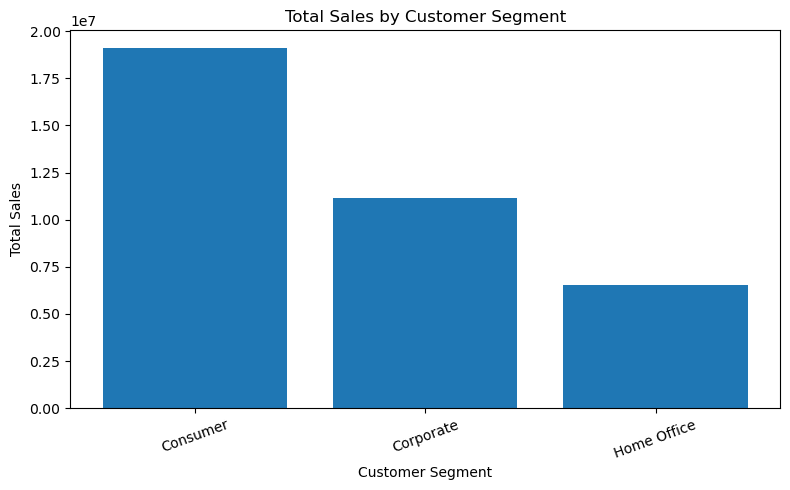

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["Customer Segment"],
    segment_summary["Total_Sales"]
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

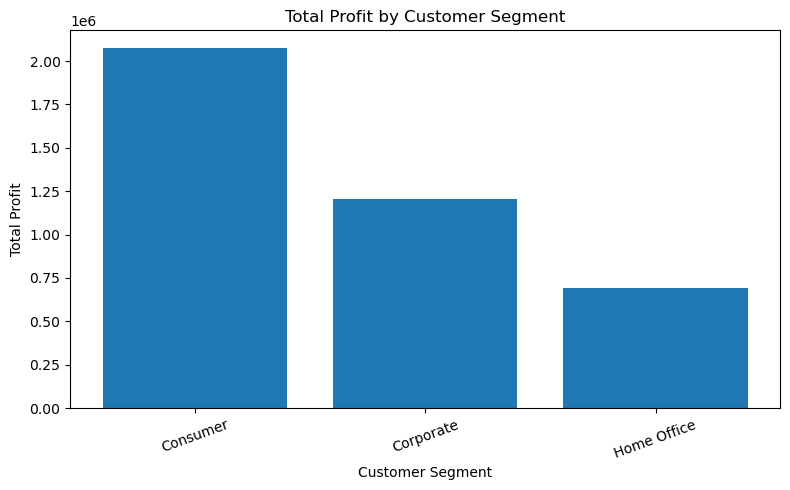

In [24]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["Customer Segment"],
    segment_summary["Total_Profit"]
)

plt.title("Total Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

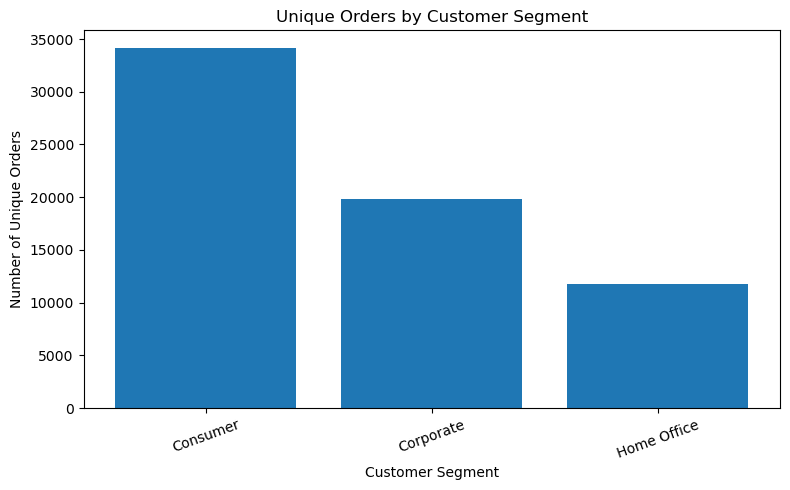

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["Customer Segment"],
    segment_summary["Total_Orders"]
)

plt.title("Unique Orders by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

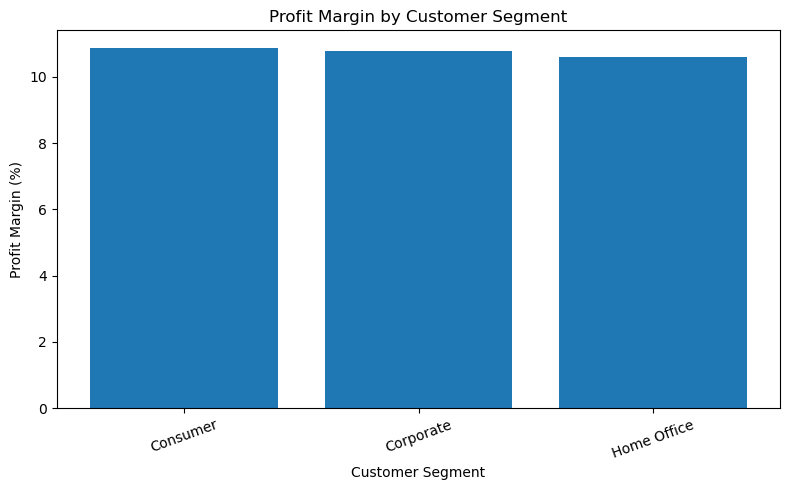

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["Customer Segment"],
    segment_summary["Profit_Margin_Percent"]
)

plt.title("Profit Margin by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [27]:
output_dir = r"C:\Users\HP\Internship\reports\segment_comparison"

os.makedirs(output_dir, exist_ok=True)

segment_summary.to_csv(
    os.path.join(output_dir, "segment_comparison_summary.csv"),
    index=False
)

print("Summary saved successfully")

Summary saved successfully


In [28]:
plt.savefig(
    os.path.join(output_dir, "sales_by_segment.png"),
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

## Segment Comparison — Key Findings

### Objective
To compare customer segments based on total sales, total profit, unique orders, and profit margin.

### Analysis Performed
- Compared total sales across customer segments.
- Evaluated total profit generated by each segment.
- Compared the number of unique orders.
- Calculated profit margin percentage.
- Created visualizations to identify differences between segments.

### Conclusion
The segment comparison helps identify which customer segments contribute more to sales and profitability. The final business conclusions will be based on the calculated summary table and visualizations.